# StratScout | Reading a Mirage attack from the radar

A coach reviewing an opponent wants to know how the team entered a site. The final position tells only part of the story. Two attacks can end on B, but an apartments-only entry and an apartments–short split put pressure on different defenders. StratScout takes a **manually cut clip of one tactic** and ranks five possibilities using the spectator radar.

Follow one recorded clip from coloured icons to a prediction, then check how often the same models were right across **45 reviewed clips from two held-out matches**. The figures and tables below are saved for reading on GitHub.

**To run it yourself.** Clone the repository, follow the [Python 3.13 setup](../README.md#windows-setup), and make sure `ffmpeg` and `ffprobe` are on PATH. In that Python environment install `ipykernel` and select it in your notebook editor, or install `jupyterlab` and launch it from the repository. Choose **Restart Kernel and Run All**. The default run uses one of three bundled clips, the saved checkpoints and the committed results. The first inference downloads the ImageNet ResNet-18 weights (about 45 MB) unless they are already cached. The full clip ZIP is optional.

## 1. From a pro match to one reviewed tactic

We recorded full-screen CS2 replays on Mirage at **2560 × 1440, 60 fps, constant 2× playback**, with the radar orientation, scale and team colours fixed. The `python -m stratscout process-recordings` command crops the minimap, restores normal game time and exports aligned 5, 10 and 30 fps versions. The submitted clips use **494 × 500 pixels at 10 fps**. A reviewer marked the start and end of each committed attack or retake, and a second reviewer checked the label. A fake followed by a real attack can yield a clip of just the later commitment.

| Reviewed class | What the label means on Mirage |
|---|---|
| `A_DIRECT` | An A attack through ramp, palace or both. |
| `A_SPLIT` | The ramp/palace group and a mid-to-connector group participate in the same A attack. |
| `B_DIRECT` | The B commitment comes through apartments. A separate lurker can be elsewhere. |
| `B_SPLIT` | Apartments and mid-to-short groups participate in the same B attack. |
| `RETAKE` | CTs attempt to regain a planted site. The attempt counts even if it fails. |

The label belongs to the segment. Map regions provide model inputs later. [Recording workflow](../docs/recording-setup.md) · [Tactic definitions and edge cases](../docs/tactic-definitions.md)

In [1]:
import json
import shutil
import sys
from pathlib import Path
from tempfile import TemporaryDirectory
from uuid import uuid4

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "stratscout" / "web_analysis.py").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook inside a clone of the StratScout repository.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
if any(shutil.which(tool) is None for tool in ("ffmpeg", "ffprobe")):
    raise RuntimeError("Install FFmpeg with ffprobe, then restart the kernel.")

from stratscout import web_analysis
from stratscout.bomb import SPECTATOR_T_HUE
from stratscout.config import TACTIC_CLASSES
from stratscout.live_preview import detect, spectator_context
from stratscout.media import probe
from stratscout.tactic_features import match_background
from stratscout.tactic_tcn import classification_metrics

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

runs = root / "runs"
samples = root / "deploy" / "streamlit" / "samples"
index = pd.read_csv(runs / "clip-data-2026-11-16" / "index.csv")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Bundled clips")
for path in sorted(samples.glob("*.mp4")):
    print(" ", path.name)

Bundled clips
  navi-falcons-mirage-cologne-major.jx.s029.mp4
  vitality-falcons-mirage-esl-pro-league-season-24.jx.s001.mp4
  vitality-falcons-mirage-esl-pro-league-season-24.jx.s006.mp4


In [2]:
# Choose any of the three filenames printed above, then run the cells below.
sample_name = "vitality-falcons-mirage-esl-pro-league-season-24.jx.s006.mp4"
clip = samples / sample_name
if not clip.is_file():
    raise FileNotFoundError(f"Choose a bundled MP4 from the list above: {sample_name}")

info = probe(clip)
print(f"{clip.name}\n{info['width']} × {info['height']} pixels | "
      f"{info['fps']:g} fps | {info['frames']} frames | {info['duration_seconds']:.1f} s")

vitality-falcons-mirage-esl-pro-league-season-24.jx.s006.mp4
494 × 500 pixels | 10 fps | 171 frames | 17.1 s


In [3]:
if index.groupby("match")["split"].nunique().max() != 1:
    raise ValueError("A match appears in more than one split.")
eligible = index.loc[~index["uncertain"]]
counts = pd.crosstab(eligible["label"], eligible["split"]).reindex(TACTIC_CLASSES)
counts = counts[["train", "test"]].rename(columns={"train": "Training", "test": "Held out"})
counts.loc["Total"] = counts.sum()
print(f"{len(index)} reviewed clips exported across {index['match'].nunique()} matches. "
      f"{len(eligible)} used after excluding the uncertain Spirit training segment.")
display(counts.rename_axis("Tactic", axis="index").rename_axis(None, axis="columns"))

128 reviewed clips exported across 6 matches. 127 used after excluding the uncertain Spirit training segment.


,Training,Held out
Tactic,,
A_DIRECT,15,15
B_DIRECT,24,6
A_SPLIT,14,6
B_SPLIT,9,5
RETAKE,20,13
Total,82,45


## 2. What does the detector see?

The detector separates yellow T icons and cyan CT icons using colour and shape, handles touching icons and checks an orange C4 badge separately. A carried badge can cover the player completely. When its rim supports a carrier and the detector has no nearby T centre, it records an **inferred carrier**. A dropped badge alone adds no player.

These are three individual frames from the exported clip. A ring marks a visible icon centre, a square marks the badge, and an × marks a carrier inferred underneath it. Watch which icons change position across the three views. A sequence of centres does not establish player identity.

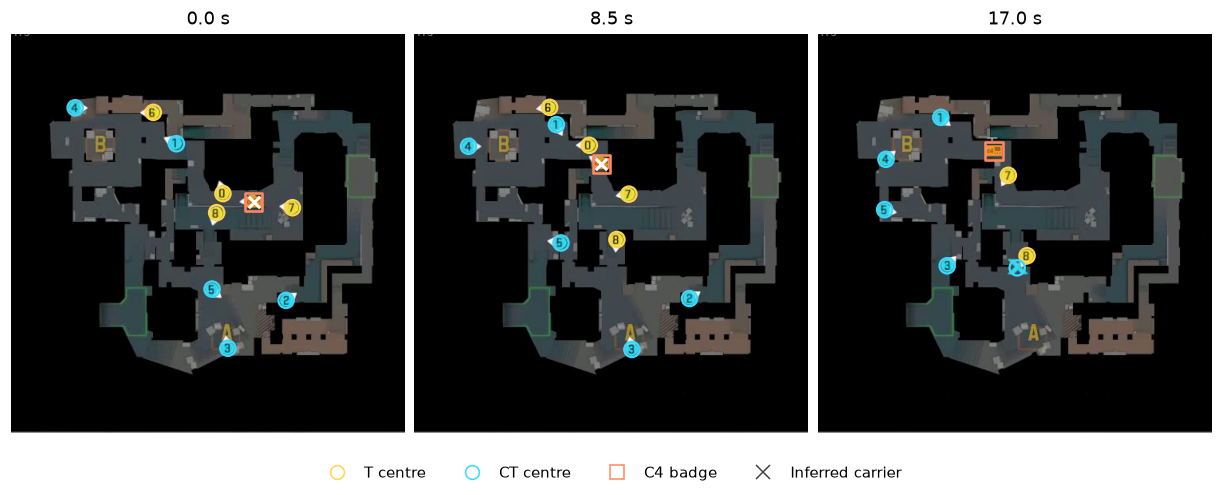

In [4]:
background = match_background([clip])
context = spectator_context()
colours = {"T": "#ffd44d", "CT": "#37d9ff"}
capture = cv2.VideoCapture(str(clip))
fig, axes = plt.subplots(1, 3, figsize=(11, 4.4), layout="constrained")
try:
    for ax, frame_number in zip(axes, np.linspace(0, info["frames"] - 1, 3).astype(int)):
        capture.set(cv2.CAP_PROP_POS_FRAMES, int(frame_number))
        ok, bgr = capture.read()
        if not ok:
            raise ValueError(f"Could not decode frame {frame_number}.")
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        found = detect(rgb, 4, SPECTATOR_T_HUE, background, context=context)
        ax.imshow(rgb)
        for x, y, team in found["players"]:
            ax.scatter(x, y, s=100, facecolors="none", edgecolors=colours[team], linewidths=1.5)
        if found["bomb"] is not None:
            badge = found["bomb"]
            ax.scatter(badge["x"], badge["y"], s=135, marker="s",
                       facecolors="none", edgecolors="#ff885e", linewidths=1.7)
        if found["carrier"] is not None:
            ax.scatter(*found["carrier"], s=55, marker="x", color="white", linewidths=2)
        ax.set_title(f"{frame_number / info['fps']:.1f} s")
        ax.axis("off")
finally:
    capture.release()
handles = [Line2D([], [], ls="", marker=m, markerfacecolor="none",
                  markeredgecolor=c, markersize=9, label=label)
           for m, c, label in [("o", colours["T"], "T centre"), ("o", colours["CT"], "CT centre"),
                               ("s", "#ff885e", "C4 badge"), ("x", "#444444", "Inferred carrier")]]
fig.legend(handles=handles, loc="outside lower center", ncols=4, frameon=False)
plt.show()

## 3. Run the same analysis as the website

This cell calls the application's round-analysis entry point. It stages the selected MP4 in a temporary workspace and treats the whole clip as one interval. The app prepares a 10 fps analysis copy, detects the player and bomb icons, extracts features and loads both three-seed ensembles. The saved stage record below comes from **this run**. Labels and demo coordinates are used later for comparison.

The overlay above uses the original exported frames. The app analyses its own FFmpeg-prepared copy, so small pixel differences are possible. With one clip, the background estimate also has less evidence for distinguishing a stationary player from the map.

In [5]:
with TemporaryDirectory(prefix="stratscout-showcase-") as folder:
    workspace = Path(folder)
    video_id, segment_id = str(uuid4()), str(uuid4())
    shutil.copyfile(clip, workspace / f"{video_id}.mp4")
    # round_number and phase are display metadata. Neither is used to score a tactic.
    segment = dict(id=segment_id, round_number=1, phase="attack",
                   start_s=0.0, end_s=info["duration_seconds"])
    job = web_analysis.queue_analysis(workspace, video_id)
    web_analysis.run_analysis(workspace, video_id, job["analysis_id"], [segment],
                              playback_speed=1, prepared_clip=True, min_confidence=0.6)
    completed = web_analysis.get_analysis(workspace, video_id)
    if completed["status"] != "complete":
        raise RuntimeError(completed.get("error") or "Analysis did not finish.")
    result = completed["results"][0]
    stages = web_analysis.get_pipeline(workspace, video_id, segment_id)

det = result["detection"]
print(f"{det['frames']} frames analysed | {det['player_icon_observations']:,} icon observations "
      f"(summed across frames) | badge visible in {det['bomb_visible_frames']} frames")
print(f"{stages['steps']} feature rows reached each temporal model.")

171 frames analysed | 1,575 icon observations (summed across frames) | badge visible in 167 frames
86 feature rows reached each temporal model.


### How does a moving dot become a model input?

Every second frame contributes a feature row, so **10 video frames per second become five model steps per second**. The 72 detector channels describe team occupancy, movement, spread and bomb state. A frozen ResNet-18 extracts 512 appearance values from the same frame. A PCA transform fitted on the training clips reduces these to 32 values, giving the selected TCN 104 inputs per step.

The chart follows T occupancy in the main approach regions. Compare **apartments and short** for B, or **ramp/palace and connector** for A. Darker cells indicate more estimated T players in the region, averaged within the app's display intervals. Route occupancy helps explain the evidence available to the model. A player standing on short can still be a lurker.

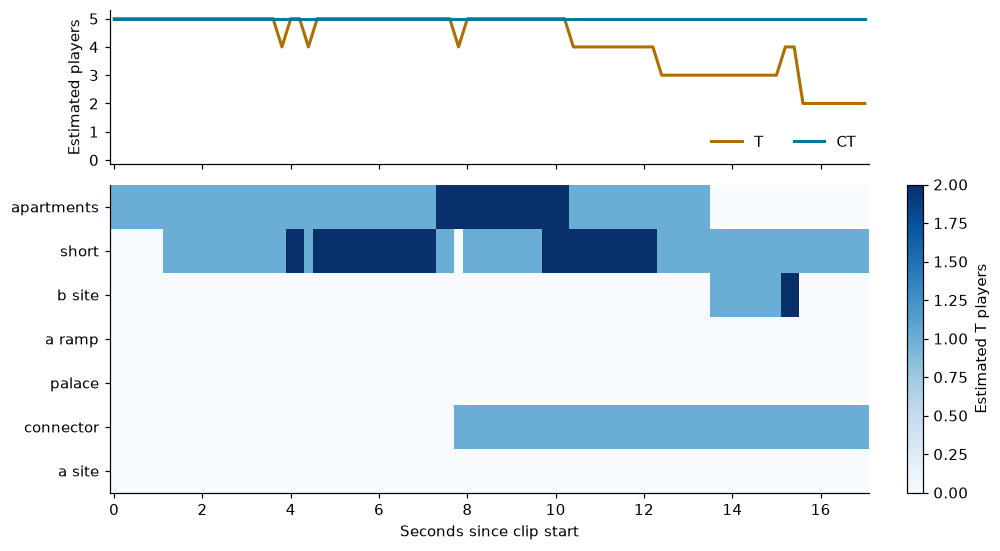

In [6]:
times = np.asarray(stages["column_times_s"])
regions = stages["detection"]["t_regions"]
routes = ["apartments", "short", "b_site", "a_ramp", "palace", "connector", "a_site"]
rows = [regions["labels"].index(route) for route in routes]
occupancy = np.asarray(regions["values"])[rows]
fig, (counts_ax, map_ax) = plt.subplots(2, 1, figsize=(9, 4.9), sharex=True,
                                       height_ratios=(1, 2), layout="constrained")
for team, key, colour in [("T", "t_seen", "#ad7000"), ("CT", "ct_seen", "#007b99")]:
    counts_ax.plot(times, stages["detection"]["counts"][key], label=team, color=colour, lw=2)
counts_ax.set(ylabel="Estimated players", ylim=(-0.15, 5.3), yticks=[0, 1, 2, 3, 4, 5])
counts_ax.legend(ncols=2, frameon=False, loc="lower right")
spacing = (times[1] - times[0]) / 2 if len(times) > 1 else 0.1
edges = np.r_[times[0] - spacing, (times[:-1] + times[1:]) / 2, times[-1] + spacing]
heat = map_ax.pcolormesh(edges, np.arange(len(routes) + 1), occupancy,
                         cmap="Blues", vmin=0, vmax=max(1, occupancy.max()))
map_ax.set(yticks=np.arange(len(routes)) + 0.5, yticklabels=[r.replace("_", " ") for r in routes],
           xlabel="Seconds since clip start", ylim=(len(routes), 0))
fig.colorbar(heat, ax=map_ax, label="Estimated T players")
plt.show()

**Reading the default Vitality–Falcons clip.** T estimates appear in both apartments and short during the opening part of the clip. B-site activity appears later, at roughly 14 seconds. That sequence is consistent with the reviewed B split. The connector signal is also a reminder that a few occupied radar regions alone cannot determine the class.

## 4. Which tactic did the models predict?

The **temporal convolutional network (TCN)** looks for motion patterns across neighbouring time steps. Five residual blocks use increasing dilations to combine short and longer windows. The **compact pooled gated recurrent unit (GRU)** updates a hidden state as each feature row arrives. Both models summarise the sequence with mean and maximum pooling and rank the same five classes. Each ensemble averages three trained seeds.

The bars show the ensembles’ output probabilities for this clip. The human label is read from the reviewed index **after** prediction. Agreement on one clip is a demonstration of the pipeline. The next section measures performance.

In [7]:
tcn = stages["tcn"]["architecture"]
gru = stages["gru"]["architecture"]
print(f"TCN: {stages['tcn']['input_width']} inputs per step; block dilations {tcn['dilations']}; "
      f"receptive field up to {tcn['receptive_field_s']:g} s before pooling.")
print(f"GRU: {gru['projection']} projected features + {gru['time_inputs']} time values per step; "
      f"{gru['hidden']} hidden units. Mean and maximum states give {gru['readout_width']} classifier inputs.")

TCN: 104 inputs per step; block dilations [1, 2, 4, 8, 16]; receptive field up to 25 s before pooling.
GRU: 8 projected features + 2 time values per step; 16 hidden units. Mean and maximum states give 32 classifier inputs.


Reviewed tactic: B_SPLIT
TCN: B_SPLIT (97.0%)
Compact pooled GRU: B_SPLIT (98.5%)


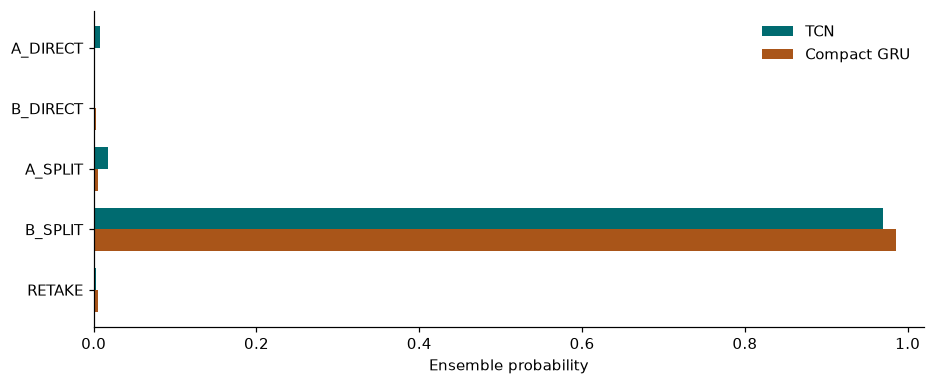

In [8]:
predictions = result["predictions"]
model_names = {"tcn": "TCN", "gru": "Compact pooled GRU"}
scores = pd.DataFrame({name: predictions[key]["probabilities"] for key, name in model_names.items()})
scores = scores.reindex(TACTIC_CLASSES)
human_label = index.set_index("clip_id").at[clip.stem, "label"]
print(f"Reviewed tactic: {human_label}")
for key, name in model_names.items():
    prediction = predictions[key]
    flag = " (flagged for review)" if prediction["uncertain"] else ""
    print(f"{name}: {prediction['tactic']} ({prediction['confidence']:.1%}){flag}")

ax = scores.plot.barh(figsize=(8.6, 3.6), color=["#006b70", "#a95519"], width=0.72)
ax.set(xlim=(0, 1.02), xlabel="Ensemble probability", ylabel="")
ax.invert_yaxis()
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. How well did the two stages work?

**Player positions.** On four development matches, the team compared vision output with positions recorded in the original game demos. Odd rounds were used to fit spatial alignment and the timing offset. Even rounds were scored, sampling once per second. A player counts as found when a same-team detection is paired within **12 radar pixels**. The extra rate is the share of detections left unmatched. The T totals include inferred carriers. This measures location accuracy on those matches. Player identity and the five tactical labels are separate questions. [Detector verification](../docs/detector-check.md)

In [9]:
checked = read_json(root / "docs/evidence/detector-check-2026-11-27/summary.json")
rows = []
for team in ("T", "CT"):
    item = checked["groups"]["pooled"][team]["all"]
    rows.append({"Team": team, "Player-frames": item["players"], "Found within 12 px": f"{item['found_rate']:.1%}",
                 "Extra detections": f"{item['extra_rate']:.1%}", "Median error (px)": round(item["median_px"], 2),
                 "90th percentile (px)": round(item["p90_px"], 2)})
display(pd.DataFrame(rows).set_index("Team"))

,Player-frames,Found within 12 px,Extra detections,Median error (px),90th percentile (px)
Team,,,,,
T,13871,95.5%,2.2%,0.84,2.24
CT,13853,98.3%,0.5%,0.71,1.92


**Selecting a tactic model.** During development each of four training matches took a turn as the validation match. When choosing how long to train, the nested procedure used only the remaining matches. Macro-F1 gives each represented class equal weight, which matters because `B_SPLIT` has only nine eligible training examples. The table includes an image-only ResNet baseline alongside the models trained on shared detector and appearance features. A pooled classifier discards the sequence order and provides a control for the TCN.

In [10]:
nested_tcn = read_json(runs / "tactic-tcn-clipdata-nested-20261120/summary.json")["models"]
image_baseline = read_json(runs / "tactic-temporal-20261116/mean/summary.json")["model"]["macro_f1"]
validation = {"Mean pooling · images only": (image_baseline["mean"], image_baseline["std"])}
for key, name in [("tcn", "TCN"), ("control", "Pooled control")]:
    item = nested_tcn[key]
    validation[name] = (item["nested_macro_f1_mean_over_seeds"], item["nested_macro_f1_seed_sd"])
for folder, name in [("gru", "Compact pooled GRU"), ("mean", "Mean pooling · shared features"), ("thirds", "Three-segment pooling")]:
    item = read_json(runs / "tactic-clipdata-nested-20261120" / folder / "summary.json")
    metric = item["model"]["macro_f1"]
    validation[name] = (metric["mean"], metric["std"])
dev = pd.DataFrame.from_dict(validation, orient="index", columns=["Nested macro-F1", "Seed SD"])
display(dev.sort_values("Nested macro-F1", ascending=False).round(3))

,Nested macro-F1,Seed SD
TCN,0.849,0.021
Pooled control,0.809,0.035
Mean pooling · shared features,0.796,0.016
Compact pooled GRU,0.792,0.033
Three-segment pooling,0.763,0.048
Mean pooling · images only,0.518,0.034


**Judging the selected model.** The team selected the TCN on development results, then scored the final ensembles on NaVi–Falcons and Vitality–Falcons. The next cell recomputes accuracy and macro-F1 from the saved clip-level predictions. It also shows which tactics the TCN confused. Every ensemble gets one prediction per clip; the three seeds do not count as three independent test cases.

,Correct / clips,Accuracy,Macro-F1
Ensemble,,,
TCN,42 / 45,93.3%,0.927
Compact pooled GRU,43 / 45,95.6%,0.963


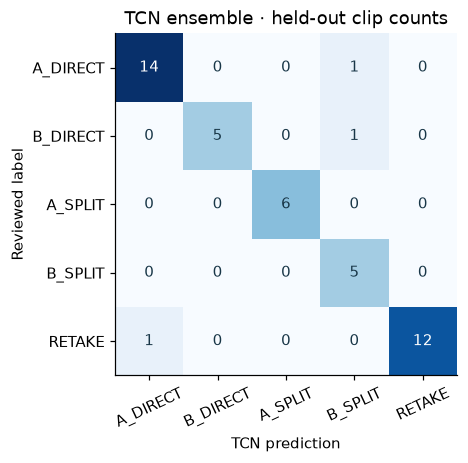

In [11]:
tcn_rows = pd.read_csv(runs / "tactic-tcn-clipdata-final/predictions.csv").query("model == 'tcn'")
gru_rows = pd.read_csv(runs / "tactic-gru-clipdata-test-20261121/predictions.csv").query("seed == 'ensemble'")
reference = eligible.loc[eligible["split"].eq("test")].set_index("clip_id")["label"].sort_index()
class_number = {label: i for i, label in enumerate(TACTIC_CLASSES)}
test_results = {}
summary = []
for name, records in [("TCN", tcn_rows), ("Compact pooled GRU", gru_rows)]:
    scored = records.set_index("clip_id").sort_index()
    if not scored.index.is_unique or not scored["true"].equals(reference):
        raise ValueError(f"{name} test records disagree with the held-out clip index.")
    metric = classification_metrics(scored["true"].map(class_number), scored["predicted"].map(class_number))
    test_results[name] = metric
    summary.append({"Ensemble": name, "Correct / clips": f"{(scored.true == scored.predicted).sum()} / {len(scored)}",
                    "Accuracy": f"{metric['accuracy']:.1%}", "Macro-F1": round(metric["macro_f1"], 3)})
display(pd.DataFrame(summary).set_index("Ensemble"))

matrix = np.array(test_results["TCN"]["confusion"])
fig, ax = plt.subplots(figsize=(6.1, 4.1), layout="constrained")
ax.imshow(matrix, cmap="Blues", vmin=0)
for (row, col), count in np.ndenumerate(matrix):
    ax.text(col, row, str(count), ha="center", va="center",
            color="white" if count > matrix.max() / 2 else "#183647")
ax.set(xticks=range(len(TACTIC_CLASSES)), yticks=range(len(TACTIC_CLASSES)),
       xticklabels=TACTIC_CLASSES, yticklabels=TACTIC_CLASSES,
       xlabel="TCN prediction", ylabel="Reviewed label", title="TCN ensemble · held-out clip counts")
ax.tick_params(axis="x", labelrotation=25)
plt.show()

The TCN correctly classified **42 of 45** held-out clips. One reviewed `B_DIRECT` was called `B_SPLIT`; a second route changes the class only when it participates in the same attack. The GRU's three-seed ensemble scored higher on these two matches, though averaged over single seeds the TCN was slightly ahead (0.897 against 0.890), and the TCN had the stronger nested development result. Two test matches with some familiar teams and only five `B_SPLIT` clips give limited evidence about new opponents or broadcasts.

The offline evaluation built a background from multiple clips per match. A single upload uses a clip-derived background, so its probabilities can differ from the frozen test predictions. Overlapping icons, a hidden bomb carrier and an unfamiliar radar layout can all change the features. Full-match segmentation, other maps and persistent player identity remain outside the demonstrated workflow.

### Optional experiment: fit the TCN from the released data

The live example above uses the saved checkpoints. To train a new model, extract the [128-clip release](https://github.com/FraggyVz/CV-DL/releases/tag/dataset-2026-11-16) into `data/processed/datasets/2026-11-16/`, with the two split manifests directly under `train/` and `test/`. Set the switch below to `True` for a **one-epoch development smoke test**. It uses the same shared inputs, excludes the uncertain boundary, writes a fresh local run and leaves held-out evaluation disabled. One epoch checks that training works; the submitted scores above come from the frozen experiments.

In [12]:
RUN_TRAINING = False

if RUN_TRAINING:
    import subprocess

    dataset = root / "data" / "processed" / "datasets" / "2026-11-16"
    if not all((dataset / split / "manifest.csv").is_file() for split in ("train", "test")):
        raise FileNotFoundError("Extract the released dataset as described above before enabling training.")
    output = runs / f"showcase-training-{uuid4().hex[:8]}"
    subprocess.run([
        sys.executable, "-m", "stratscout", "train-tactics", "--dataset", str(dataset),
        "--clip-data", str(runs / "clip-data-2026-11-16"), "--models", "tcn",
        "--exclude-uncertain", "--seeds", "1", "--epochs", "1", "--output", str(output),
    ], cwd=root, check=True)
    print(f"Development report: {output.relative_to(root) / 'report.md'}")
else:
    print("Optional training skipped.")

Optional training skipped.


## 6. Run it in the apps

| Route | What to do | When to use it |
|---|---|---|
| **Streamlit Community Cloud** | Open [StratScout](https://stratscout.streamlit.app/), choose **Use sample clips**, add the clip ending in `s006` and choose **Analyse Round 1**. | Try the walkthrough in a browser using a prepared radar clip. |
| **Local Docker app** | From the repository root run `docker compose up --build`, open [localhost:8000](http://127.0.0.1:8000), and upload one tactic clip. | Keep multiple match workspaces on disk. Full-screen input also requires the matching crop profile. |
| **This notebook** | Change `sample_name`, rerun from the selection cell and compare the two model scores. | Inspect how a particular clip reaches its prediction alongside the independent evaluation. |

To reproduce training, the [dataset release](https://github.com/FraggyVz/CV-DL/releases/tag/dataset-2026-11-16) contains the 128 cropped clips and their manifests. The [submission guide](../README.md#reproduce-the-submitted-results) gives the extraction and training commands. For the full experiments, see the [shared features](clip-data-walkthrough.ipynb), [TCN walkthrough](tactic-tcn-walkthrough.ipynb), [model comparison](tactic-model-comparison.ipynb) and [held-out evaluation](tactic-final-test.ipynb).